In [86]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
from scipy.stats import norm
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go

**load data**

In [43]:
# # saving only the added delta values and biosample/DHS inds
# for i in range(1, 4):
#     print(i)
#     #load npz file
#     filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
#     cycle_np_file = np.load(filename)
    
#     biosample_inds_to_1 = cycle_np_file['biosample_inds_to_1']
#     DHS_inds_to_1 = cycle_np_file['DHS_inds_to_1']
#     biosample_inds_to_0 = cycle_np_file['biosample_inds_to_0']
#     DHS_inds_to_0 = cycle_np_file['DHS_inds_to_0']
    
#     inds_to_0 = np.int64(DHS_inds_to_0) + (n_DHSs * np.int64(biosample_inds_to_0))
#     inds_to_1 = np.int64(DHS_inds_to_1) + (n_DHSs * np.int64(biosample_inds_to_1))
    
#     diff_flat_array = cycle_np_file['diff_flat_array']
    
#     #in order of first removed and first added to last removed and last added
#     sorted_inds_to_0 = inds_to_0[np.argsort(diff_flat_array[inds_to_0])]
#     sorted_inds_to_1 = inds_to_1[np.argsort(-diff_flat_array[inds_to_1])]
    
#     #corresponding delta vals
#     sorted_diff_removed = diff_flat_array[sorted_inds_to_0]
#     sorted_diff_added = diff_flat_array[sorted_inds_to_1]
    
#     #save
#     new_filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_added_removed_delta_flatinds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220315.npz'
#     np.savez(new_filename, added_delta=sorted_diff_added, removed_delta=sorted_diff_removed, added_flat_inds=sorted_inds_to_1, removed_flat_inds=sorted_inds_to_0)

1
2
3


In [106]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 4):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_added_removed_delta_flatinds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220315.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [31]:
added_delta_all_cycles[1].shape[0]

1598035

In [3]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [4]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [107]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [67]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [54]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

**Tracking calls over cycles**

In [109]:
cycle0_dhs_arr = cycle0_dhs_arr.astype(int)

In [133]:
initial_positive = np.sum(cycle0_dhs_arr)

readded_cycle_1 = len(added_flat_inds_all_cycles[0]) - len(filtered_added_flat_inds_all_cycles[0])
readded_cycle_2 = len(added_flat_inds_all_cycles[1]) - len(filtered_added_flat_inds_all_cycles[1])
readded_cycle_3 = len(added_flat_inds_all_cycles[2]) - len(filtered_added_flat_inds_all_cycles[2])

total_call_num = cycle0_dhs_arr.shape[0]*cycle0_dhs_arr.shape[1]
intitial_negative = total_call_num - initial_positive

added_cycle_1 = len(filtered_added_flat_inds_all_cycles[0])
removed_cycle_1 = len(removed_flat_inds_all_cycles[0])

cycle_1_kept_1 = initial_positive - removed_cycle_1 - readded_cycle_1
cycle_1_kept_0 = intitial_negative - added_cycle_1

cycle_1_positive = cycle_1_kept_1 + added_cycle_1
cycle_1_negative = cycle_1_kept_0 + removed_cycle_1

added_cycle_2 = len(filtered_added_flat_inds_all_cycles[1])
removed_cycle_2 = len(removed_flat_inds_all_cycles[1])

cycle_2_kept_1 = cycle_1_positive - removed_cycle_2 - readded_cycle_2
cycle_2_kept_0 = cycle_1_negative - added_cycle_2

cycle_2_positive = cycle_2_kept_1 + added_cycle_2
cycle_2_negative = cycle_2_kept_0 + removed_cycle_2

added_cycle_3 = len(filtered_added_flat_inds_all_cycles[2])
removed_cycle_3 = len(removed_flat_inds_all_cycles[2])

cycle_3_kept_1 = cycle_2_positive - removed_cycle_3 - readded_cycle_3
cycle_3_kept_0 = cycle_2_negative - added_cycle_3

cycle_3_positive = cycle_3_kept_1 + added_cycle_3
cycle_3_negative = cycle_3_kept_0 + removed_cycle_3

In [163]:
fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 15,
      thickness = 20,
      line = dict(color = 'white', width = 0.5),
      label = ['Originally Positive', 'Originally Negative', 'Cycle 1 Positive', 'Cycle 1 Negative', 
               'Cycle 2 Positive', 'Cycle 2 Negative', 'Cycle 3 Positive', 'Cycle 3 Negative'],
      color = 'Grey'
    ),
    link = dict(
      source = [0, 0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 0, 2, 4],
      target = [2, 3, 3, 2, 4, 5, 5, 4, 6, 7, 7, 6, 2, 4, 6],
      value = [cycle_1_kept_1, removed_cycle_1, cycle_1_kept_0, added_cycle_1,
               cycle_2_kept_1, removed_cycle_2, cycle_2_kept_0, added_cycle_2,
               cycle_3_kept_1, removed_cycle_3, cycle_3_kept_0, added_cycle_3,
               readded_cycle_1, readded_cycle_2, readded_cycle_3],
      label = ['Unchanged Positive Cycle 1', 'Removed Cycle 1', 'Unchanged Negative Cycle 1', 'Added Cycle 1',
               'Unchanged Positive Cycle 2', 'Removed Cycle 2', 'Unchanged Negative Cycle 2', 'Added Cycle 2',
               'Unchanged Positive Cycle 3', 'Removed Cycle 3', 'Unchanged Negative Cycle 3', 'Added Cycle 3',
               'Readded Cycle 1', 'Readded Cycle 2', 'Readded Cycle 3'],
      color = ['#D3D3D3', 'Red', '#D3D3D3', 'Green', '#D3D3D3', 'Red', '#D3D3D3', 'Green', 
               '#D3D3D3', 'Red', '#D3D3D3', 'Green', 'Teal', 'Teal', 'Teal']
  ))])

fig.update_layout(title_text='Pregression of Call Values: Delta Threshold Flip, Threshold=-0.5/0.5', font_size=10)
fig.show()

**delta values over cycles**

In [84]:
all_cycles_delta_mean = []
all_cycles_delta_std = []
for i in range(1, 4):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_diffflat_sortedDHS_sortedbiosample_to0inds_to1inds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
    cycle_np_file = np.load(filename)
    diff_flat_array = cycle_np_file['diff_flat_array']
    
    cycle_delta_mean = np.mean(diff_flat_array)
    all_cycles_delta_mean.append(cycle_delta_mean)
    
    cycle_delta_std = np.std(diff_flat_array)
    all_cycles_delta_std.append(cycle_delta_std)
    
    del diff_flat_array
    
all_cycles_delta_mean = np.array(all_cycles_delta_mean)
all_cycles_delta_std = np.array(all_cycles_delta_std)

1
2
3


In [39]:
all_cycles_delta_mean[1]

0.0016744162

In [79]:
ci_95 = []
for i in range(3):
    ci_95.append(norm.interval(0.95, loc=all_cycles_delta_mean[i], scale=all_cycles_delta_std[i]/np.sqrt(n_DHSs*733)))
ci_95 = np.array(ci_95)

In [70]:
all_cycles_delta_mean

[0.0040282393, 0.0016744162, 0.00082437956]

In [65]:
ci_95

array([[0.00402395, 0.00403253],
       [0.0016725 , 0.00167634],
       [0.00082313, 0.00082563]])

In [86]:
all_cycles_delta_std*2

array([0.22468145, 0.10050343, 0.06530941], dtype=float32)

Text(0.5, 1.0, 'Delta Values for All Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

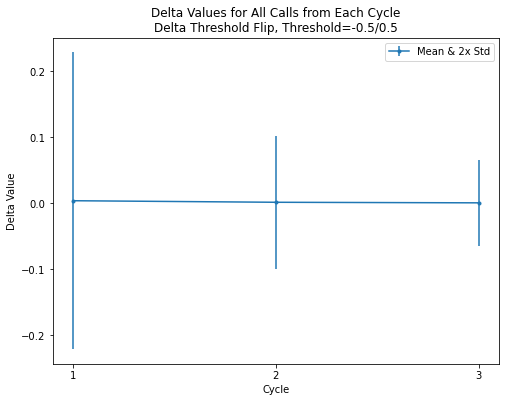

In [93]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.errorbar(np.arange(1, 4), all_cycles_delta_mean, all_cycles_delta_std*2, marker='.')

plt.xticks([1, 2, 3])
plt.legend(['Mean & 2x Std'])
# plt.yscale('symlog')
plt.xlabel('Cycle')
plt.ylabel('Delta Value')
plt.title('Delta Values for All Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

**Removing 1 to 1 interactions**

In [114]:
filtered_added_delta_all_cycles = []
filtered_added_flat_inds_all_cycles = []

for i in range(3):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
    
    n_biosamples, n_DHSs = dhs_arr.shape
    
    added_flat_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        if ~dhs_arr[biosample, dhs]:
            added_flat_inds_single_cycle.append(flat_ind)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
    filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

0
1
2


In [6]:
for i in range(len(filtered_added_flat_inds_all_cycles)):
    print('Percent of calls changed from 1 to 1 in cycle %s: %s' %(i+1, np.round((1-len(filtered_added_flat_inds_all_cycles[i])/len(added_flat_inds_all_cycles[i]))*100, 4)))

Percent of calls changed from 1 to 1 in cycle 1: 2.0766
Percent of calls changed from 1 to 1 in cycle 2: 2.2327
Percent of calls changed from 1 to 1 in cycle 3: 1.966


Text(0.5, 1.0, 'Delta Values for Removed Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

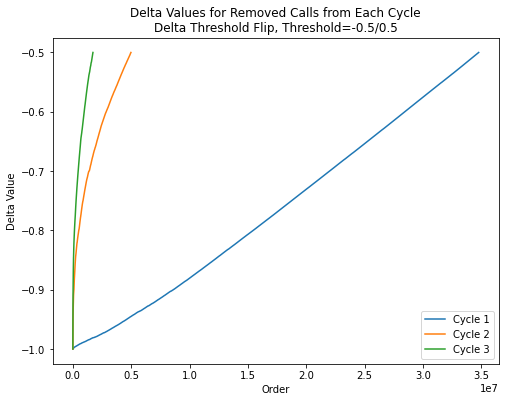

In [55]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.plot(np.arange(len(removed_delta_all_cycles[i])), removed_delta_all_cycles[i])

plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'])
# plt.yticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
# plt.yscale('symlog')
# plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Removed Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

Text(0.5, 1.0, 'Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

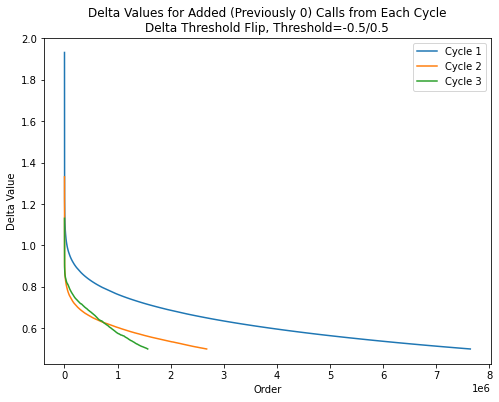

In [56]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.plot(np.arange(len(filtered_added_delta_all_cycles[i])), filtered_added_delta_all_cycles[i])

plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'])
# plt.yticks([-1, -0.999995, -0.99999, -0.999985, -0.99998], [-1, -0.999995, -0.99999, -0.999985, -0.99998])
# plt.yscale('symlog')
# plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Added (Previously 0) Calls from Each Cycle\nDelta Threshold Flip, Threshold=-0.5/0.5')

**Plotting delta vs peak signal and peak signal vs mean signal for added and removed calls**

In [7]:
#finding peak signal values of added calls
removed_peak_signal_all_cycles = []
for i in range(3):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2


Text(0.5, 1.0, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

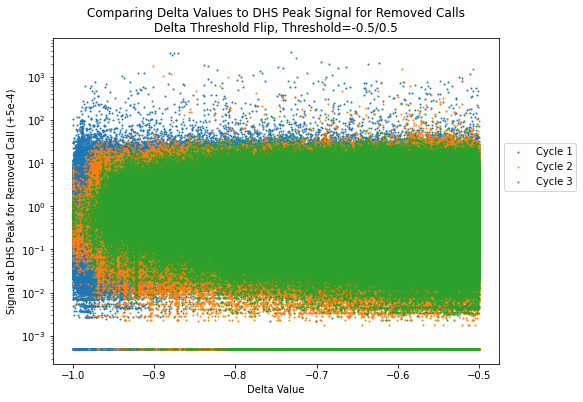

In [64]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.scatter(removed_delta_all_cycles[i], removed_peak_signal_all_cycles[i]+0.0005, s=1)

# plt.xlim([1.2, 2])
# plt.ylim([0.0004, 110])
plt.yscale('log')
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'], loc=(1.01, 0.53))
plt.xlabel('Delta Value')
plt.ylabel('Signal at DHS Peak for Removed Call (+5e-4)')
plt.title('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

In [8]:
#finding peak signal values of added calls
filtered_added_peak_signal_all_cycles = []
for i in range(3):
    print(i)
    filtered_added_peak_signal_single_cycle = []
    for biosample, dhs in zip((filtered_added_flat_inds_all_cycles[i] // n_DHSs), (filtered_added_flat_inds_all_cycles[i] % n_DHSs)):
        filtered_added_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    filtered_added_peak_signal_single_cycle = np.array(filtered_added_peak_signal_single_cycle)
    filtered_added_peak_signal_all_cycles.append(filtered_added_peak_signal_single_cycle)

0
1
2


Text(0.5, 1.0, 'Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

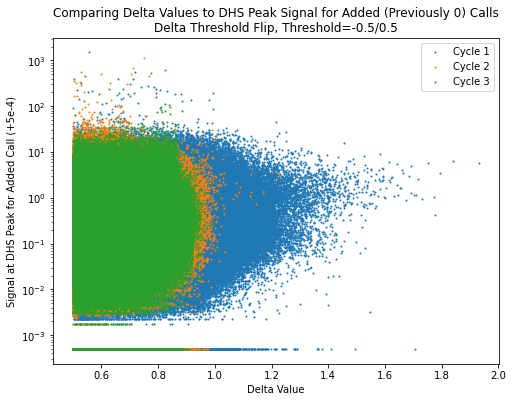

In [65]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.scatter(filtered_added_delta_all_cycles[i], filtered_added_peak_signal_all_cycles[i]+0.0005, s=1)
#     plt.xlim([1.2, 2])
#     plt.ylim([0.0004, 110])

plt.yscale('log')
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'])

plt.xlabel('Delta Value')
plt.ylabel('Signal at DHS Peak for Added Call (+5e-4)')
plt.title('Comparing Delta Values to DHS Peak Signal for Added (Previously 0) Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

In [68]:
#finding average signal value of DHS of removed calls
removed_mean_signal_all_cycles = []
for i in range(3):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(removed_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    removed_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [69]:
#finding average signal value of DHS of added calls
filtered_added_mean_signal_all_cycles = []
for i in range(3):
    mean_signal_vals_single_cycle = np.array(DHS_metadata.loc[(filtered_added_flat_inds_all_cycles[i] % n_DHSs)]['mean_signal'])
    filtered_added_mean_signal_all_cycles.append(mean_signal_vals_single_cycle)

In [72]:
for i in removed_mean_signal_all_cycles:
    print(np.max(i))
    print(np.min(i))

427.859746848568
0.0122875
427.859746848568
0.0468340695652174
427.859746848568
0.068395464516129


Text(0.5, 1.08, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Threshold Flip, Threshold=-0.5/0.5')

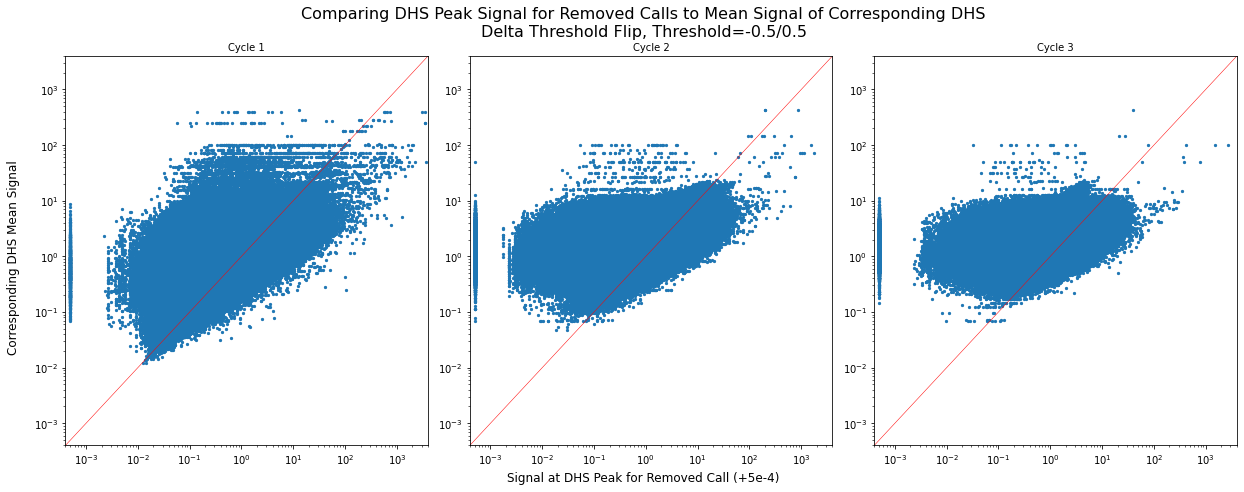

In [80]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,6))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ax, i in zip(axes, range(3)):
    scat = ax.scatter(removed_peak_signal_all_cycles[i]+0.0005, removed_mean_signal_all_cycles[i], s=5)
    ax.set_title('Cycle ' + str(i+1), fontsize=10)
    ax.set_xlim([0.0004, 4000])
    ax.set_ylim([0.0004, 4000])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(5000)-1, np.arange(5000)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.08)

Text(0.5, 1.08, 'Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Threshold Flip, Threshold=-0.5/0.5')

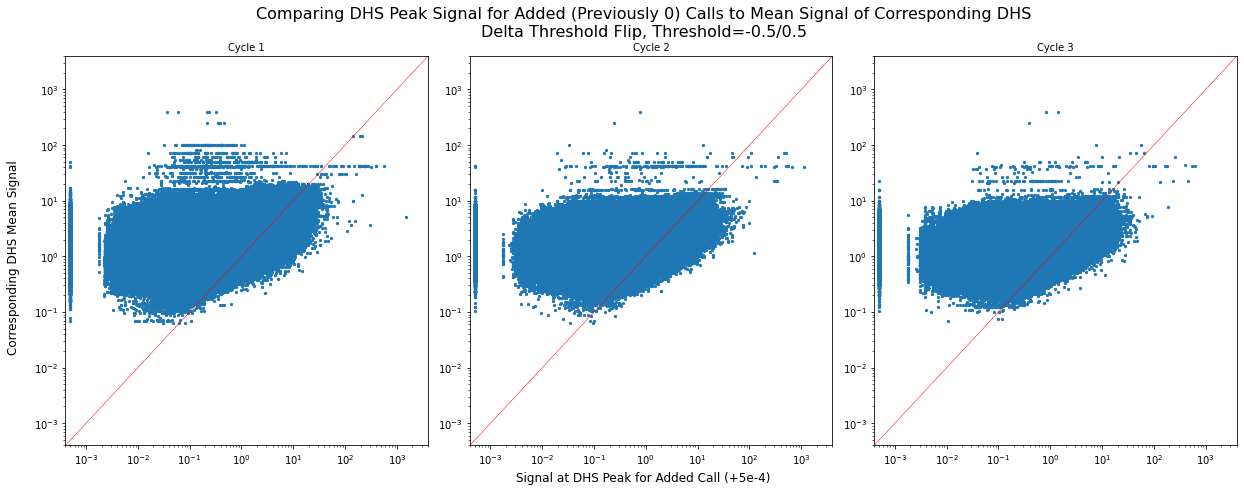

In [79]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,6))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ax, i in zip(axes, range(3)):
    scat = ax.scatter(filtered_added_peak_signal_all_cycles[i]+0.0005, filtered_added_mean_signal_all_cycles[i], s=5)
    ax.set_title('Cycle ' + str(i+1), fontsize=10)
    ax.set_xlim([0.0004, 4000])
    ax.set_ylim([0.0004, 4000])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(5000)-1, np.arange(5000)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call (+5e-4)', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added (Previously 0) Calls to Mean Signal of Corresponding DHS\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.08)

In [82]:
data[(data<0.1) & (data>0.001)].shape

(363759,)

In [83]:
data.shape

(1566617,)

In [117]:
filtered_added_peak_signal_all_cycles_counts = []
b = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
for c in range(3):
    data = filtered_added_peak_signal_all_cycles[c]
    cycle_count = []
    for i in range(len(b)-1):
        cycle_count.append(len(data[(data>=b[i]) & (data<b[i+1])]))
    cycle_count = cycle_count/np.sum(cycle_count)
    filtered_added_peak_signal_all_cycles_counts.append(np.array(cycle_count))

In [118]:
removed_peak_signal_all_cycles_counts = []
b = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
for c in range(3):
    data = removed_peak_signal_all_cycles[c]
    cycle_count = []
    for i in range(len(b)-1):
        cycle_count.append(len(data[(data>=b[i]) & (data<b[i+1])]))
    cycle_count = cycle_count/np.sum(cycle_count)
    removed_peak_signal_all_cycles_counts.append(np.array(cycle_count))

Text(0.5, 1.07, 'Peak Signal for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

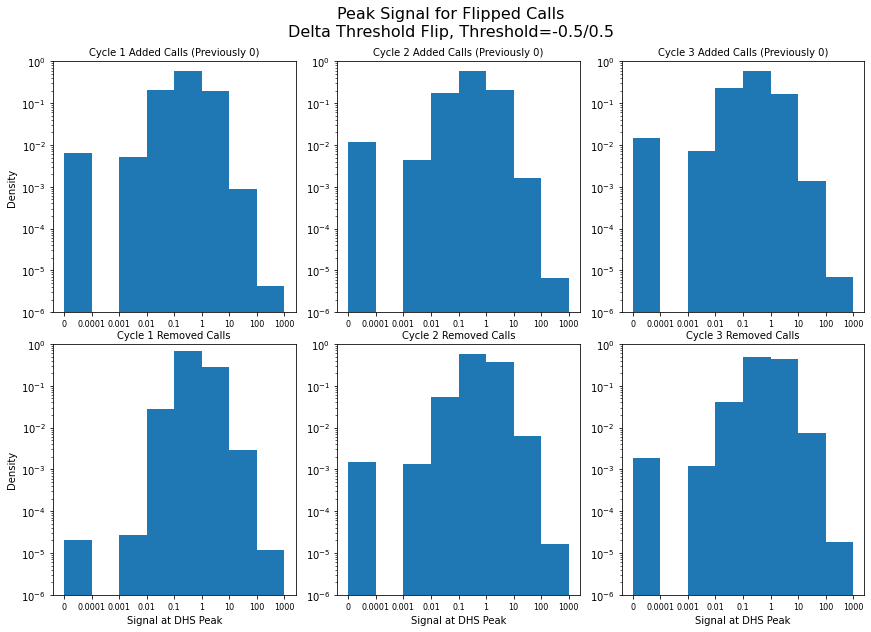

In [119]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(3):
    axes[ind].bar(np.arange(len(filtered_added_peak_signal_all_cycles_counts[ind])), 
                  filtered_added_peak_signal_all_cycles_counts[ind], 
                  align='edge',
                  width=1)
    axes[ind+3].bar(np.arange(len(removed_peak_signal_all_cycles_counts[ind])), 
                    removed_peak_signal_all_cycles_counts[ind], 
                    align='edge',
                    width=1)
    axes[ind].set_title('Cycle %s Added Calls (Previously 0)' %(ind+1), fontsize=10)
    axes[ind+3].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
    axes[ind].set_yscale('log')
    axes[ind+3].set_yscale('log')
    
    axes[ind].set_ylim([1e-6, 1])
    axes[ind+3].set_ylim([1e-6, 1])
    
#     axes[ind].set_xscale('log')
#     axes[ind+3].set_xscale('log')
    
    axes[ind].set_xticks(np.arange(len(filtered_added_peak_signal_all_cycles_counts[ind])+1))
    axes[ind+3].set_xticks(np.arange(len(removed_peak_signal_all_cycles_counts[ind])+1))
    axes[ind].set_xticklabels(['0', '0.0001', '0.001', '0.01', '0.1', '1', '10', '100', '1000'], fontsize=8)
    axes[ind+3].set_xticklabels(['0', '0.0001', '0.001', '0.01', '0.1', '1', '10', '100', '1000'], fontsize=8)
    
axes[3].set_xlabel('Signal at DHS Peak')
axes[4].set_xlabel('Signal at DHS Peak')
axes[5].set_xlabel('Signal at DHS Peak')
# axes[1].set_yticks([])
# axes[2].set_yticks([])
# axes[4].set_yticks([])
# axes[5].set_yticks([])
axes[0].set_ylabel('Density')
axes[3].set_ylabel('Density')
plt.suptitle('Peak Signal for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'Peak Signal for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

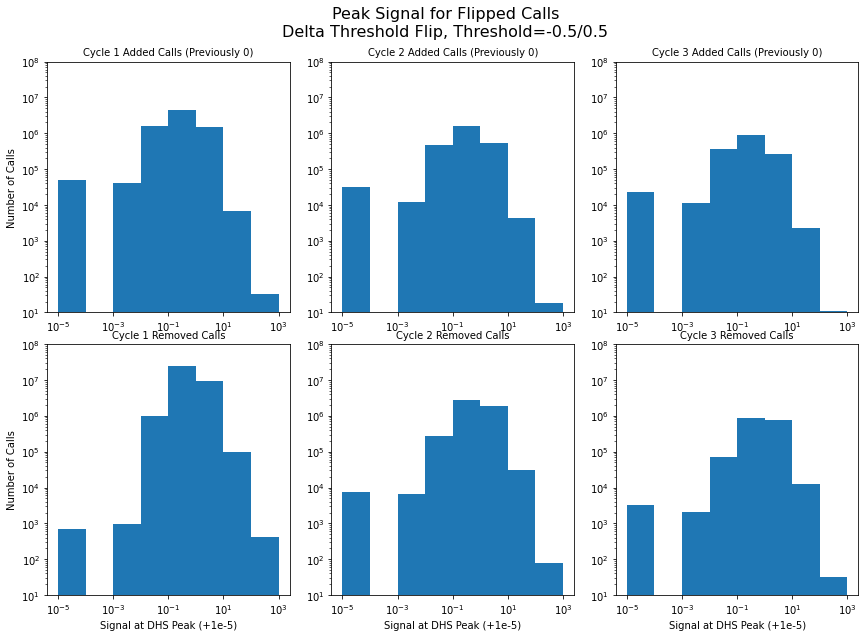

In [75]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

b = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

axes = axes.ravel()
for ind in range(3):
    axes[ind].hist(filtered_added_peak_signal_all_cycles[ind]+0.00001, bins=b)
    axes[ind+3].hist(removed_peak_signal_all_cycles[ind]+0.00001, bins=b)
    axes[ind].set_title('Cycle %s Added Calls (Previously 0)' %(ind+1), fontsize=10)
    axes[ind+3].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
    axes[ind].set_yscale('log')
    axes[ind+3].set_yscale('log')
    
    axes[ind].set_ylim([10, 1e8])
    axes[ind+3].set_ylim([10, 1e8])
    
    axes[ind].set_xscale('log')
    axes[ind+3].set_xscale('log')
    
    axes[ind].set_xticks(b[::2])
    axes[ind+3].set_xticks(b[::2])
#     axes[ind].set_xticklabels([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3], fontsize=8)
#     axes[ind+3].set_xticklabels([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3], fontsize=8)
    
axes[3].set_xlabel('Signal at DHS Peak (+1e-5)')
axes[4].set_xlabel('Signal at DHS Peak (+1e-5)')
axes[5].set_xlabel('Signal at DHS Peak (+1e-5)')
# axes[1].set_yticks([])
# axes[2].set_yticks([])
# axes[4].set_yticks([])
# axes[5].set_yticks([])
axes[0].set_ylabel('Number of Calls')
axes[3].set_ylabel('Number of Calls')
plt.suptitle('Peak Signal for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)

**Biosample SPOT Scores**

In [52]:
#how many biosamples have call changes in 10 cycles
changed_biosamples = set()
for i in range(3):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    for j in biosample_inds:
        changed_biosamples.add(j)
len(changed_biosamples)

733

In [55]:
filtered_added_biosample_spot_scores_all_cycles = []
for i in range(3):
    biosample_inds = filtered_added_flat_inds_all_cycles[i] // n_DHSs
    filtered_added_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

In [56]:
removed_biosample_spot_scores_all_cycles = []
for i in range(3):
    biosample_inds = removed_flat_inds_all_cycles[i] // n_DHSs
    removed_biosample_spot_scores_all_cycles.append(np.array(biosample_df.loc[biosample_inds]['DCC SPOT score']))

Text(0.5, 1.0, 'Comparing Delta Values to Corresponding Biosample SPOT Scores for Added (Previously 0) Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

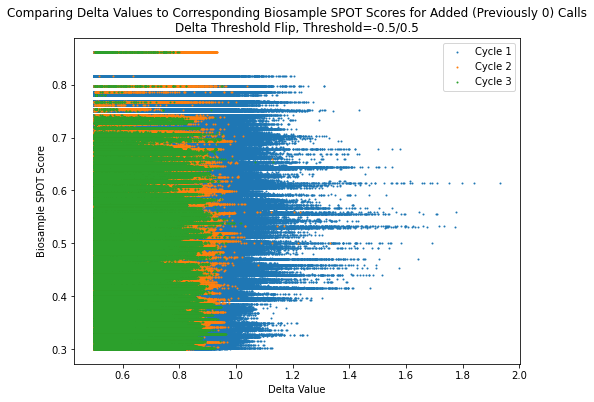

In [87]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.scatter(filtered_added_delta_all_cycles[i], filtered_added_biosample_spot_scores_all_cycles[i], s=1)
#     plt.xlim([1.2, 2])
#     plt.ylim([0.3, 0.8])
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'])

plt.xlabel('Delta Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Delta Values to Corresponding Biosample SPOT Scores for Added (Previously 0) Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

Text(0.5, 1.0, 'Comparing Delta Values to Corresponding Biosample SPOT Scores for Removed Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

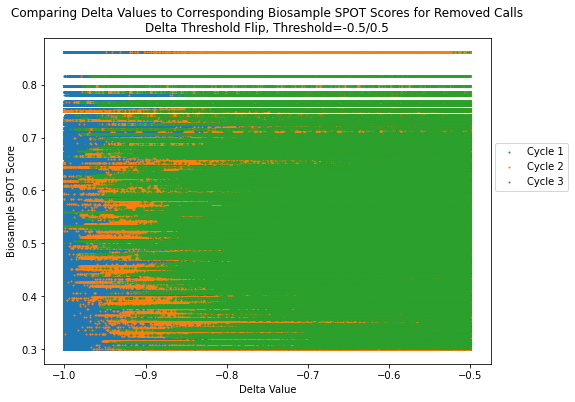

In [88]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

for i in range(3):
    plt.scatter(removed_delta_all_cycles[i], removed_biosample_spot_scores_all_cycles[i], s=1)
#     plt.xlim([1.2, 2])
    
plt.legend(['Cycle 1', 'Cycle 2', 'Cycle 3'], loc=(1.01, 0.53))
plt.xlabel('Delta Value')
plt.ylabel('Biosample SPOT Score')
plt.title('Comparing Delta Values to Corresponding Biosample SPOT Scores for Removed Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

In [120]:
for i in range(3):
    print(np.mean(filtered_added_biosample_spot_scores_all_cycles[i]))
    
for i in range(3):
    print(np.mean(removed_biosample_spot_scores_all_cycles[i]))

0.5354049044661788
0.5110478839901642
0.5122610583824894
0.5244919424230557
0.53765313041405
0.5234479331204447


Text(0.5, 1.07, 'SPOT Scores for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

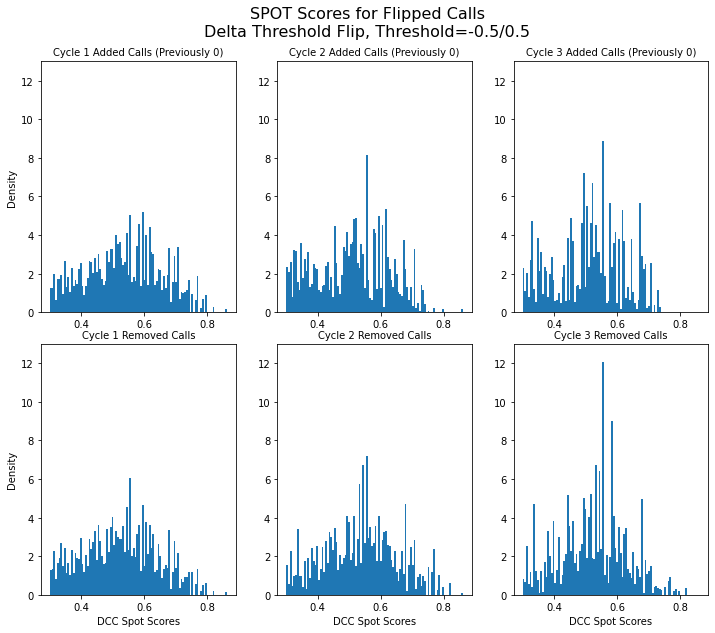

In [73]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(3):
    axes[ind].hist(filtered_added_biosample_spot_scores_all_cycles[ind], bins=100, density=True)
    axes[ind+3].hist(removed_biosample_spot_scores_all_cycles[ind], bins=100, density=True)
    axes[ind].set_title('Cycle %s Added Calls (Previously 0)' %(ind+1), fontsize=10)
    axes[ind+3].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
#     axes[ind].set_ylim([0, 250000])
#     axes[ind+3].set_ylim([0, 1200000])
    axes[ind].set_ylim([0, 13])
    axes[ind+3].set_ylim([0, 13])
    
axes[3].set_xlabel('DCC Spot Scores')
axes[4].set_xlabel('DCC Spot Scores')
axes[5].set_xlabel('DCC Spot Scores')
# axes[1].set_yticks([])
# axes[2].set_yticks([])
# axes[4].set_yticks([])
# axes[5].set_yticks([])
axes[0].set_ylabel('Density')
axes[3].set_ylabel('Density')
plt.suptitle('SPOT Scores for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)

Text(0.5, 1.07, 'SPOT Scores for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5')

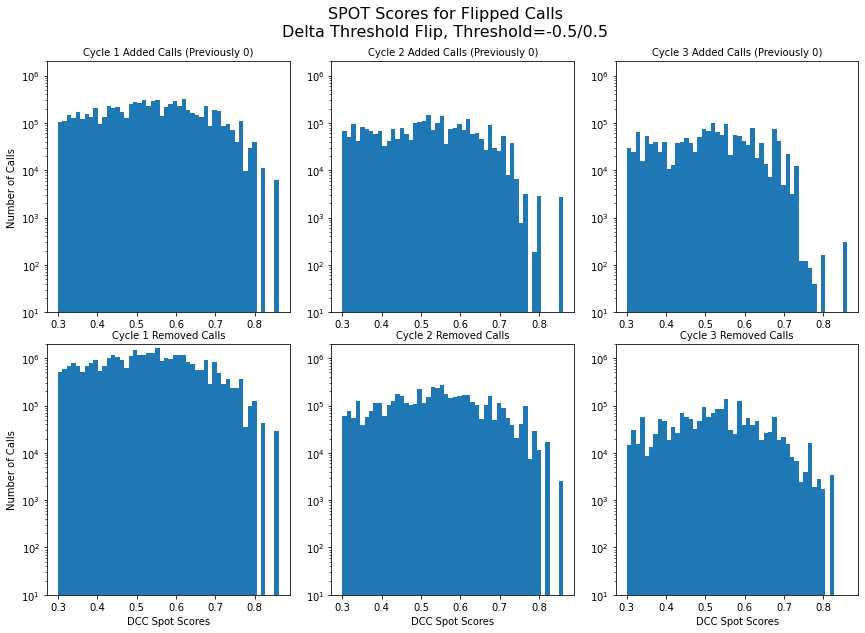

In [64]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(3):
    axes[ind].hist(filtered_added_biosample_spot_scores_all_cycles[ind], bins=50)
    axes[ind+3].hist(removed_biosample_spot_scores_all_cycles[ind], bins=50)
    axes[ind].set_title('Cycle %s Added Calls (Previously 0)' %(ind+1), fontsize=10)
    axes[ind+3].set_title('Cycle %s Removed Calls' %(ind+1), fontsize=10)
#     axes[ind].set_ylim([0, 250000])
#     axes[ind+3].set_ylim([0, 1200000])
#     axes[ind].set_ylim([0, 13])
#     axes[ind+3].set_ylim([0, 13])
    axes[ind].set_yscale('log')
    axes[ind+3].set_yscale('log')
    axes[ind].set_ylim([10, 2e6])
    axes[ind+3].set_ylim([10, 2e6])
    
axes[3].set_xlabel('DCC Spot Scores')
axes[4].set_xlabel('DCC Spot Scores')
axes[5].set_xlabel('DCC Spot Scores')
# axes[1].set_yticks([])
# axes[2].set_yticks([])
# axes[4].set_yticks([])
# axes[5].set_yticks([])
axes[0].set_ylabel('Number of Calls')
axes[3].set_ylabel('Number of Calls')
plt.suptitle('SPOT Scores for Flipped Calls\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)